# 01 · Volume over time

Grain here is **cases at latest version, nullified removed** (`case_latest_T`) unless stated. Time axis is `init_year_T` (year of first FDA receipt, `init_fda_dt`; legacy has no `init_fda_dt`, so it falls back to `fda_dt` of the latest ISR) or `fda_year_T` (receipt of the latest version). Never `event_dt`, which is missing or partial too often.

Things to look for:
- the 2012 Q3 / Q4 AERS to FAERS migration step
- June 2015 mandatory electronic submission
- the consumer share overtaking physicians
- 2020 to 2021 COVID era distortions
- any recent quarter that looks incomplete (the most recent quarter always is, follow-ups are still arriving)

It reads a release folder (`RELEASE` in the first code cell, or the setting `OPEN_ALTIO_RELEASE`), read only. No release yet? Build one with `open-altio demo` (FDA's latest quarter) or `open-altio build` (every quarter FDA published).

In [1]:
import matplotlib.pyplot as plt

from open_altio.faers.insights.cards.notebook import (
    SERIES,
    mark_quarters,
    mark_years,
    quarter_ticks,
    setup,
    title,
)
from open_altio.faers.insights.source import connect

setup()
# The release folder this notebook reads; None reads $OPEN_ALTIO_RELEASE.
# No release yet? Build one with `open-altio demo` or `open-altio build`.
RELEASE = None
con = connect(RELEASE)  # read only; raw tables as demo_all, drug_all, ... and the derived _T tables


def q(sql):
    return con.execute(sql).fetchdf()

## Cases per year of first FDA receipt

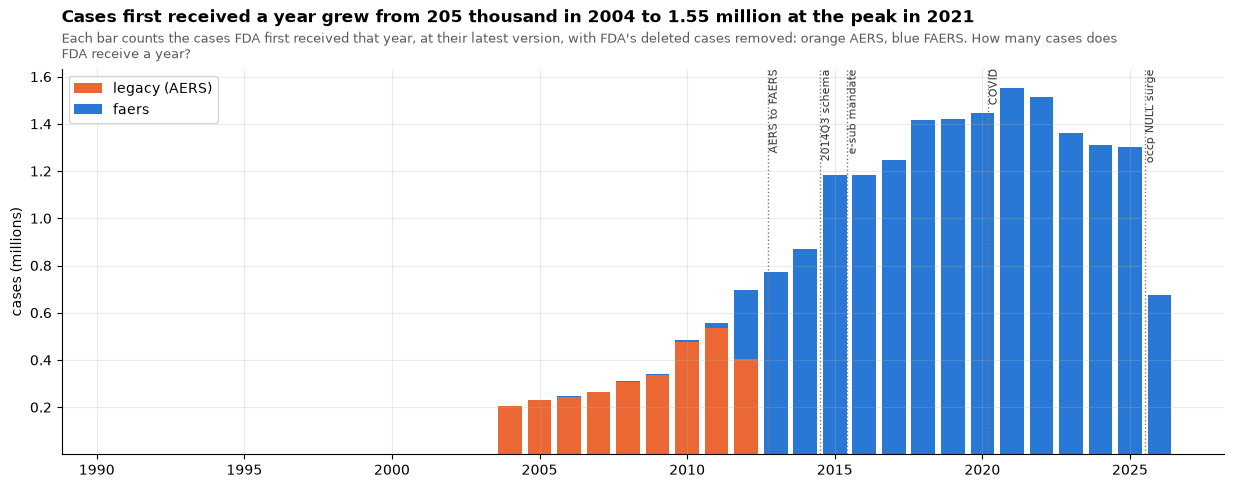

init_year_T,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
era_T,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
legacy,0,0,0,0,0,0,0,0,0,0,0,0,5,204648,230255,244796,264364,308366,334264,476068,534454,405532,0,0,0,0,0,0,0,0,0,0,0,0,0,0
faers,1,2,1,1,1,4,3,11,25,14,49,86,179,373,545,998,1483,2544,4362,7824,20362,292861,771533,871780,1184785,1182389,1245946,1417739,1421943,1444552,1553042,1514621,1361157,1309004,1302289,673266
total,1,2,1,1,1,4,3,11,25,14,49,86,184,205021,230800,245794,265847,310910,338626,483892,554816,698393,771533,871780,1184785,1182389,1245946,1417739,1421943,1444552,1553042,1514621,1361157,1309004,1302289,673266


In [2]:
yr = q(
    "select init_year_T, era_T, count(*) n from case_latest_T where init_year_T between 1990 and 2026 group by all order by 1"
)
piv = (
    yr.pivot(index="init_year_T", columns="era_T", values="n")
    .fillna(0)
    .astype(int)[["legacy", "faers"]]
)
piv["total"] = piv.sum(axis=1)
fig, ax = plt.subplots(figsize=(15, 5))
ax.bar(piv.index, piv["legacy"] / 1e6, color=SERIES[1], label="legacy (AERS)", width=0.8)
ax.bar(
    piv.index,
    piv["faers"] / 1e6,
    bottom=piv["legacy"] / 1e6,
    color=SERIES[0],
    label="faers",
    width=0.8,
)
ax.set_ylabel("cases (millions)")
peak = piv.total.idxmax()
title(
    ax,
    f"Cases first received a year grew from {piv.total[2004] / 1e3:,.0f} thousand in 2004 to "
    f"{piv.total[peak] / 1e6:.2f} million at the peak in {peak}",
    "Each bar counts the cases FDA first received that year, at their latest version, with FDA's "
    "deleted cases removed: orange AERS, blue FAERS.",
    "How many cases does FDA receive a year?",
)
ax.legend(loc="upper left")
mark_years(ax)
plt.show()
piv.T

Legacy rows with `init_year_T` before 2004 are cases whose latest ISR was received before 2004 but was published in the 2004 Q1 file: that file carried a backlog. FAERS rows with early years are cases first received before FAERS began whose latest version is in FAERS: some FDA carried over from AERS under the same case number, and each of those counts once, at its FAERS version (`rules/latest-version.md`); others FDA published late (notebook 02).

## Cases per quarter of publication

Same cases, but counted by the quarter in which their latest version was published. This is the "what arrives each quarter" view and the one that shows re-issued or incomplete quarters.

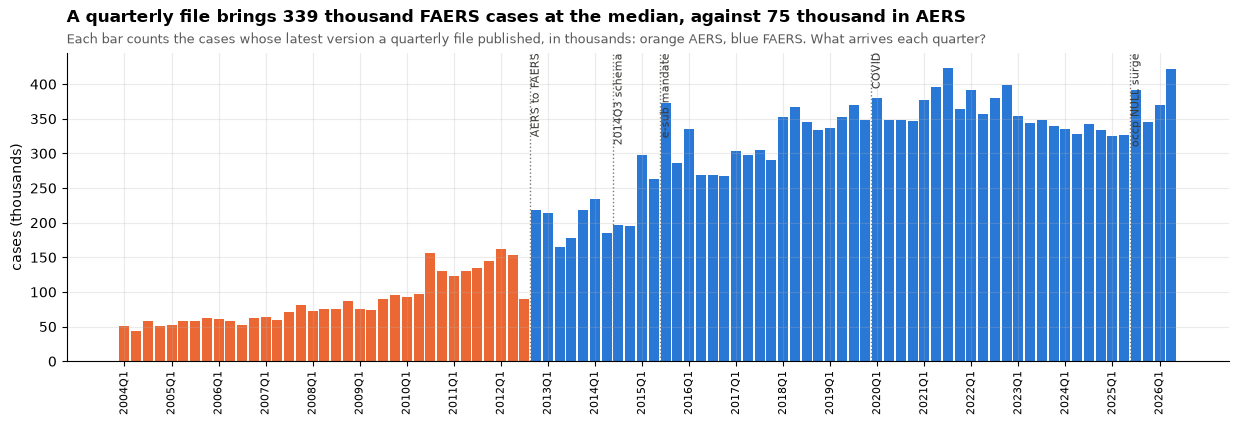

In [3]:
pq = q("select quarter_T, era_T, count(*) n from case_latest_T group by all order by 1")
fig, ax = plt.subplots(figsize=(15, 4))
ax.bar(
    range(len(pq)),
    pq.n / 1e3,
    width=0.85,
    color=[SERIES[1] if e == "legacy" else SERIES[0] for e in pq.era_T],
)
ax.set_ylabel("cases (thousands)")
by_era = pq.groupby("era_T").n.median()
title(
    ax,
    f"A quarterly file brings {by_era.faers / 1e3:,.0f} thousand FAERS cases at the median, against "
    f"{by_era.legacy / 1e3:,.0f} thousand in AERS",
    "Each bar counts the cases whose latest version a quarterly file published, in thousands: orange "
    "AERS, blue FAERS.",
    "What arrives each quarter?",
)
quarter_ticks(ax, pq.quarter_T)
mark_quarters(ax, pq.quarter_T)
plt.show()

## Report type: expedited vs periodic vs direct

`rept_cod`: EXP (15-day expedited), PER (periodic), DIR (direct to FDA via MedWatch). `30DAY` and `5DAY` are not legacy codes: they appear in 2020 and grow, mostly from a few large manufacturers; they are folded into "other" in the share chart and shown separately below.

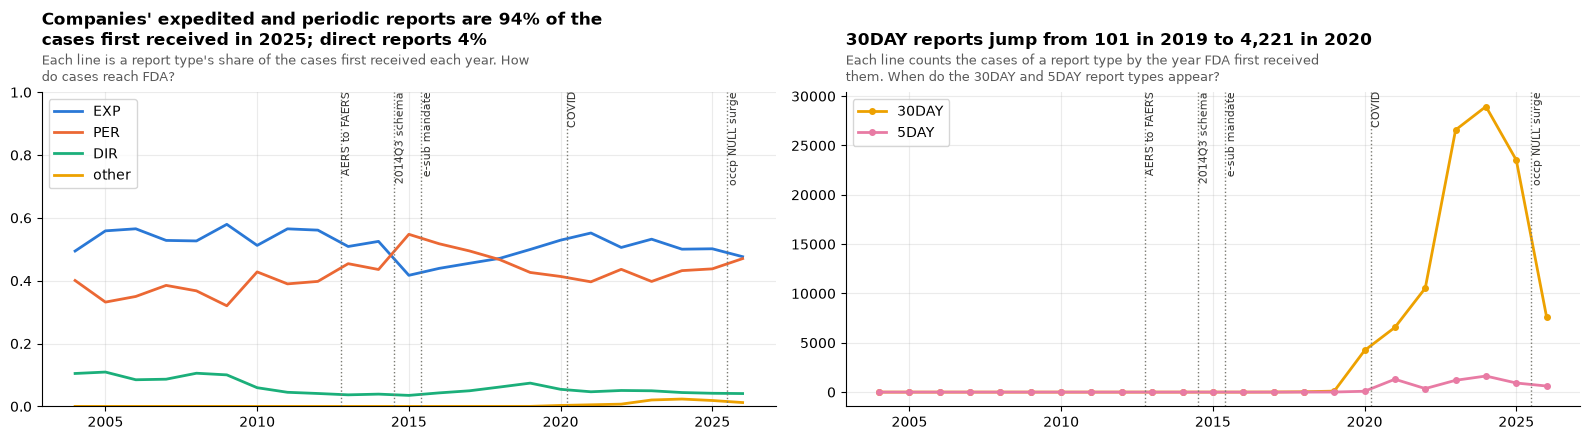

init_year_T,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
rept_cod,,,,,,,,,,,,,,,,,,,,,,,
30DAY,0,0,0,0,0,0,0,0,0,0,1,0,1,9,34,101,4221,6563,10539,26579,28952,23525,7604
5DAY,0,0,0,0,0,0,0,0,0,0,0,0,0,0,5,10,87,1305,358,1197,1629,923,617
DIR,21474,25224,20841,23007,32817,33971,28777,24896,28698,28367,34029,41477,50857,61908,87480,105320,78503,72246,76694,67643,57707,54371,27504
EXP,101383,128960,138950,140445,163750,196215,247972,313559,391838,392676,457879,494322,519503,567601,668206,710338,764305,857120,766234,724432,655040,653360,320826
NULL,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,8,0,0,0,0,0,0,0
PER,82164,76616,86003,102395,114343,108440,207143,216361,277857,350490,379871,648986,612028,616428,662014,606166,597436,615808,660796,541306,565676,570110,316715
other,0,0,0,0,0,0,0,0,0,0,1,0,1,9,39,119,4308,7868,10897,27776,30581,24448,8221


In [4]:
rt = q(
    "select init_year_T, coalesce(rept_cod,'NULL') rept_cod, count(*) n from case_latest_T where init_year_T between 2004 and 2026 group by all order by 1"
)
p = rt.pivot(index="init_year_T", columns="rept_cod", values="n").fillna(0)
main = ["EXP", "PER", "DIR"]
p["other"] = p.drop(columns=main).sum(axis=1)
share = p[main + ["other"]].div(p[main + ["other"]].sum(axis=1), axis=0)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.5))
for i, c in enumerate(main + ["other"]):
    a1.plot(share.index, share[c], label=c, color=SERIES[i])
a1.set_ylim(0, 1)
year = share.index.max() - 1
title(
    a1,
    f"Companies' expedited and periodic reports are {100 * (share.EXP[year] + share.PER[year]):.0f}% "
    f"of the cases first received in {year}; direct reports {100 * share.DIR[year]:.0f}%",
    "Each line is a report type's share of the cases first received each year.",
    "How do cases reach FDA?",
)
a1.legend()
mark_years(a1)
for i, c in enumerate(["30DAY", "5DAY"]):
    a2.plot(p.index, p[c], label=c, color=SERIES[i + 3], marker="o", ms=4)
title(
    a2,
    f"30DAY reports jump from {p['30DAY'][2019]:,.0f} in 2019 to {p['30DAY'][2020]:,.0f} in 2020",
    "Each line counts the cases of a report type by the year FDA first received them.",
    "When do the 30DAY and 5DAY report types appear?",
)
a2.legend()
mark_years(a2)
plt.tight_layout()
plt.show()
p.astype(int).T

## Who reports: occupation of the primary reporter

`occp_cod`: MD physician, PH pharmacist, OT other health professional (retired 2020), HP health professional (from 2020), LW lawyer, CN consumer. NULL is common and itself informative. Codes outside that set (RN, SALES, a date typed into the field) fold into "other".

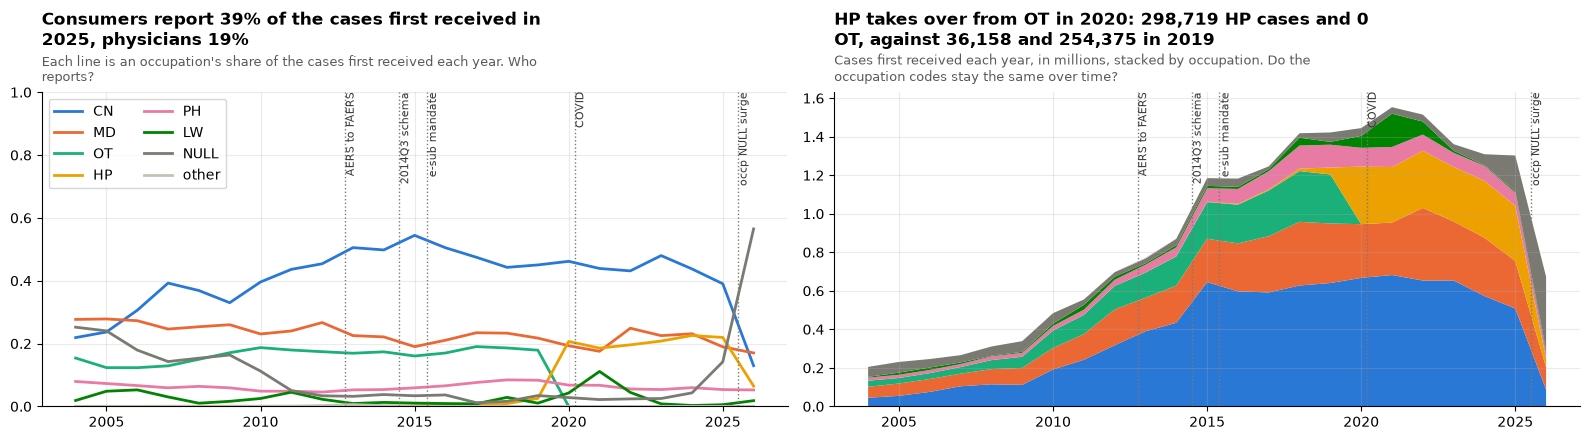

init_year_T,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
occp,,,,,,,,,,,,,,,,,,,,,,,
CN,44889,54652,75204,104340,114658,111745,191627,241989,317072,389915,434154,645026,597085,591572,627471,640284,667063,681793,653331,653362,572734,508319,87234
HP,21,29,38,105,121,179,208,296,267,443,763,2040,4016,5570,12764,36158,298719,288114,296736,283116,295478,285694,43514
LW,3848,11139,12920,8007,3157,5442,12157,25009,15827,7061,11047,12347,10684,10228,40774,14681,61737,172720,67436,10993,3827,6907,12263
MD,56762,64244,67047,65435,78816,88026,111539,133203,186331,173908,192824,225296,248994,292015,330512,309077,278732,272395,376796,306603,302595,246838,114583
NULL,51687,55479,44041,37932,47712,55384,54360,28020,23603,24696,32831,40045,43100,14778,22894,48892,40537,33703,36194,34139,56304,184826,380401
OT,31553,28461,30275,34304,46620,57856,90519,99561,121598,130549,151413,190049,200929,237065,263652,254375,0,0,0,0,0,0,0
PH,16261,16796,16269,15724,19824,19993,23478,26692,31900,40563,46682,69982,77581,94718,119672,118476,97764,104317,84128,72944,78066,69705,35271
other,0,0,0,0,2,1,4,46,1795,4398,2066,0,0,0,0,0,0,0,0,0,0,0,0


In [5]:
oc = q("""select init_year_T,
  case when occp_cod is null then 'NULL' when occp_cod in ('CN','MD','OT','PH','LW','HP') then occp_cod else 'other' end occp, count(*) n
from case_latest_T where init_year_T between 2004 and 2026 group by all order by 1""")
p = oc.pivot(index="init_year_T", columns="occp", values="n").fillna(0)
order = ["CN", "MD", "OT", "HP", "PH", "LW", "NULL", "other"]
colors = dict(zip(order, SERIES, strict=True))
share = p[order].div(p[order].sum(axis=1), axis=0)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.5))
for c in order:
    a1.plot(share.index, share[c], label=c, color=colors[c])
a1.set_ylim(0, 1)
year = share.index.max() - 1
title(
    a1,
    f"Consumers report {100 * share.CN[year]:.0f}% of the cases first received in {year}, "
    f"physicians {100 * share.MD[year]:.0f}%",
    "Each line is an occupation's share of the cases first received each year.",
    "Who reports?",
)
a1.legend(ncol=2)
mark_years(a1)
a2.stackplot(p.index, *[p[c] / 1e6 for c in order], labels=order, colors=[colors[c] for c in order])
title(
    a2,
    f"HP takes over from OT in 2020: {p.HP[2020]:,.0f} HP cases and {p.OT[2020]:,.0f} OT, against "
    f"{p.HP[2019]:,.0f} and {p.OT[2019]:,.0f} in 2019",
    "Cases first received each year, in millions, stacked by occupation.",
    "Do the occupation codes stay the same over time?",
)
mark_years(a2)
plt.tight_layout()
plt.show()
p.astype(int).T

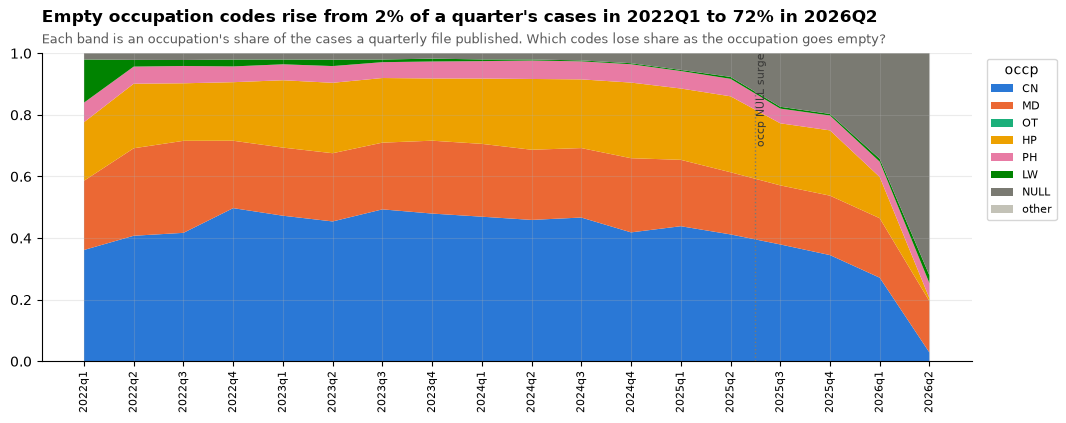

In [6]:
# the 2025Q3 collapse, by quarter of publication: which codes lose share
rq = q("""select quarter_T,
  case when occp_cod is null then 'NULL' when occp_cod in ('CN','MD','OT','PH','LW','HP') then occp_cod else 'other' end occp, count(*) n
from case_latest_T where quarter_T >= '2022q1' group by all order by 1""")
pp = rq.pivot(index="quarter_T", columns="occp", values="n").fillna(0)
pp = pp.div(pp.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(12, 4))
ax.stackplot(
    range(len(pp)),
    *[pp.get(c, 0 * pp.iloc[:, 0]) for c in order],
    labels=order,
    colors=[colors[c] for c in order],
)
ax.set_xticks(range(len(pp)))
ax.set_xticklabels(pp.index, rotation=90, fontsize=8)
ax.set_ylim(0, 1)
title(
    ax,
    f"Empty occupation codes rise from {100 * pp.NULL.iloc[0]:.0f}% of a quarter's cases in "
    f"{pp.index[0].upper()} to {100 * pp.NULL.iloc[-1]:.0f}% in {pp.index[-1].upper()}",
    "Each band is an occupation's share of the cases a quarterly file published.",
    "Which codes lose share as the occupation goes empty?",
)
ax.legend(ncol=1, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8, title="occp")
mark_quarters(ax, pp.index)
plt.show()

## Initial vs follow-up, and electronic submission

`caseversion` exists only in the FAERS era; the mean is over FAERS rows. For legacy init years it would describe the handful of long-lived cases whose latest version landed in FAERS, so those years are blank in the third panel.

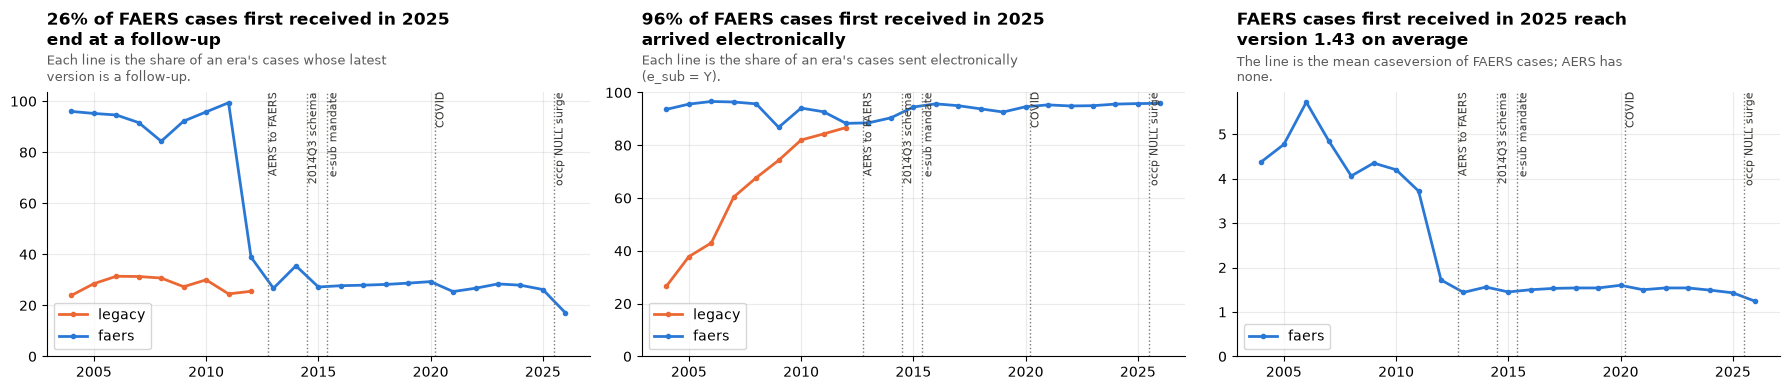

,init_year_T,era_T,cases,pct_latest_version_is_followup,pct_electronic,mean_caseversion_faers_only
0,2004,faers,373,96.0,93.6,4.38
1,2004,legacy,204648,23.9,26.6,NaN
2,2005,faers,545,95.2,95.6,4.77
3,2005,legacy,230255,28.5,37.8,NaN
4,2006,faers,998,94.6,96.6,5.72
5,2006,legacy,244796,31.4,43.0,NaN
6,2007,faers,1483,91.6,96.4,4.85
7,2007,legacy,264364,31.3,60.4,NaN
8,2008,faers,2544,84.3,95.7,4.06
9,2008,legacy,308366,30.7,67.7,NaN


In [7]:
fe = q("""select init_year_T, era_T, count(*) cases,
  round(100.0*sum(case when i_f_code='F' then 1 else 0 end)/count(*),1) as pct_latest_version_is_followup,
  round(100.0*sum(case when e_sub='Y' then 1 else 0 end)/count(*),1)    as pct_electronic,
  round(avg(caseversion_T),2) as mean_caseversion_faers_only
from case_latest_T where init_year_T between 2004 and 2026 group by 1,2 order by 1,2""")
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
year = fe.init_year_T.max() - 1
now = fe[(fe.era_T == "faers") & (fe.init_year_T == year)].iloc[0]
claims = [
    f"{now.pct_latest_version_is_followup:.0f}% of FAERS cases first received in {year} end at a "
    "follow-up",
    f"{now.pct_electronic:.0f}% of FAERS cases first received in {year} arrived electronically",
    f"FAERS cases first received in {year} reach version {now.mean_caseversion_faers_only:.2f} on "
    "average",
]
guides = [
    "Each line is the share of an era's cases whose latest version is a follow-up.",
    "Each line is the share of an era's cases sent electronically (e_sub = Y).",
    "The line is the mean caseversion of FAERS cases; AERS has none.",
]
for ax, col, claim, guide in zip(
    axes,
    ["pct_latest_version_is_followup", "pct_electronic", "mean_caseversion_faers_only"],
    claims,
    guides,
    strict=True,
):
    for era in ["legacy", "faers"]:
        s = fe[fe.era_T == era]
        if col.startswith("mean") and era == "legacy":
            continue
        ax.plot(
            s.init_year_T,
            s[col],
            label=era,
            color=SERIES[1 if era == "legacy" else 0],
            marker="o",
            ms=3,
        )
    title(ax, claim, guide)
    ax.set_ylim(0)
    ax.legend()
    mark_years(ax)
plt.tight_layout()
plt.show()
fe

## Geography

`occr_country` (where the event happened) exists from 2012 Q4, the start of the FAERS files. Before that, the only geographic hint is `rpsr_cod = 'FGN'` (foreign) in the RPSR table.

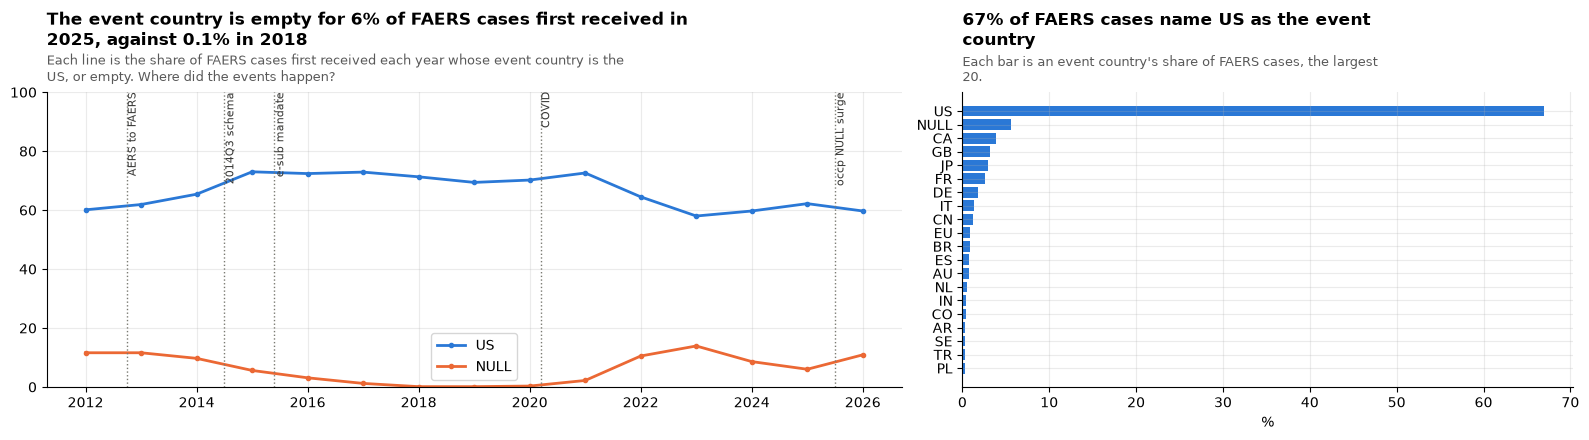

,init_year_T,pct_us,pct_country_null,n
0,2012,60.1,11.6,292861
1,2013,61.9,11.6,771533
2,2014,65.4,9.7,871780
3,2015,73.0,5.6,1184785
4,2016,72.4,3.1,1182389
5,2017,72.9,1.2,1245946
6,2018,71.3,0.1,1417739
7,2019,69.4,0.1,1421943
8,2020,70.2,0.3,1444552
9,2021,72.6,2.2,1553042


In [8]:
geo = q("""select init_year_T,
  round(100.0*sum(case when occr_country='US' then 1 else 0 end)/count(*),1) as pct_us,
  round(100.0*sum(case when occr_country is null then 1 else 0 end)/count(*),1) as pct_country_null,
  count(*) n
from case_latest_T where era_T='faers' and init_year_T between 2012 and 2026 group by 1 order by 1""")
top = q("""select coalesce(occr_country,'NULL') occr_country, count(*) n, round(100.0*count(*)/sum(count(*)) over(),2) pct
from case_latest_T where era_T='faers' group by 1 order by 2 desc limit 20""")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1.4, 1]})
a1.plot(geo.init_year_T, geo.pct_us, label="US", marker="o", ms=3)
a1.plot(geo.init_year_T, geo.pct_country_null, label="NULL", marker="o", ms=3)
a1.set_ylim(0, 100)
low = geo.loc[geo.pct_country_null.idxmin()]
title(
    a1,
    f"The event country is empty for {geo.pct_country_null.iloc[-2]:.0f}% of FAERS cases first "
    f"received in {geo.init_year_T.iloc[-2]}, against {low.pct_country_null:.1f}% in "
    f"{low.init_year_T:.0f}",
    "Each line is the share of FAERS cases first received each year whose event country is the US, "
    "or empty.",
    "Where did the events happen?",
)
a1.legend()
mark_years(a1)
a2.barh(top.occr_country[::-1], top.pct[::-1], color=SERIES[0])
title(
    a2,
    f"{top.pct.iloc[0]:.0f}% of FAERS cases name {top.occr_country.iloc[0]} as the event country",
    "Each bar is an event country's share of FAERS cases, the largest 20.",
)
a2.set_xlabel("%")
plt.tight_layout()
plt.show()
geo

## Reporter source (RPSR)

RPSR is sparsely populated in the FAERS era; in legacy it was routine. Watch the collapse.

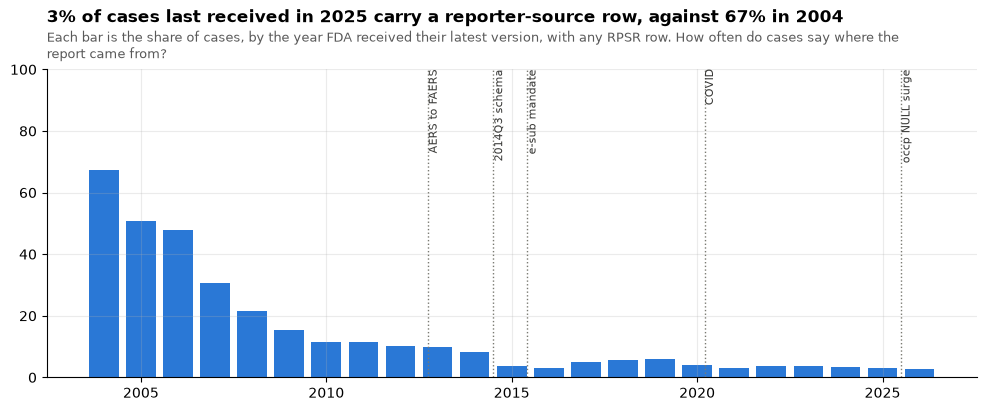

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22
yr,2004.0,2005.0,2006.0,2007.0,2008.0,2009.0,2010.0,2011.0,2012.0,2013.0,2014.0,2015.0,2016.0,2017.0,2018.0,2019.0,2020.0,2021.0,2022.0,2023.0,2024.0,2025.0,2026.0
cases,204691.0,230336.0,244914.0,264615.0,309056.0,334933.0,476721.0,534750.0,635782.0,766969.0,808336.0,1220250.0,1139984.0,1198144.0,1400377.0,1411020.0,1412282.0,1561473.0,1526831.0,1385487.0,1340057.0,1389117.0,792340.0
cases_with_rpsr,137558.0,117093.0,117640.0,81195.0,66476.0,51756.0,54541.0,61878.0,65083.0,75849.0,65456.0,43363.0,33787.0,59703.0,79546.0,84854.0,56236.0,48315.0,55744.0,52184.0,45288.0,43341.0,22513.0
pct_with_rpsr,67.2,50.8,48.0,30.7,21.5,15.5,11.4,11.6,10.2,9.9,8.1,3.6,3.0,5.0,5.7,6.0,4.0,3.1,3.7,3.8,3.4,3.1,2.8


In [9]:
rp = q("""select c.fda_year_T as yr,
  count(distinct c.caseid) cases,
  count(distinct r.primaryid) cases_with_rpsr,
  round(100.0*count(distinct r.primaryid)/count(distinct c.caseid),1) pct_with_rpsr
from case_latest_T c left join rpsr_latest_T r using (era_T, primaryid, quarter_T)
group by 1 having yr between 2004 and 2026 order by 1""")
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(rp.yr, rp.pct_with_rpsr, color=SERIES[0])
ax.set_ylim(0, 100)
title(
    ax,
    f"{rp.pct_with_rpsr.iloc[-2]:.0f}% of cases last received in {rp.yr.iloc[-2]:.0f} carry a "
    f"reporter-source row, against {rp.pct_with_rpsr.iloc[0]:.0f}% in {rp.yr.iloc[0]:.0f}",
    "Each bar is the share of cases, by the year FDA received their latest version, with any RPSR row.",
    "How often do cases say where the report came from?",
)
mark_years(ax)
plt.show()
rp.T

## Nullified cases per quarter

Only available since the deleted-case lists began (2019 Q1). The 2019 Q1 zip also carried an all-history list (`pre2019q1`, reported in the title). A spike usually means a manufacturer cleaned up a duplicate batch.

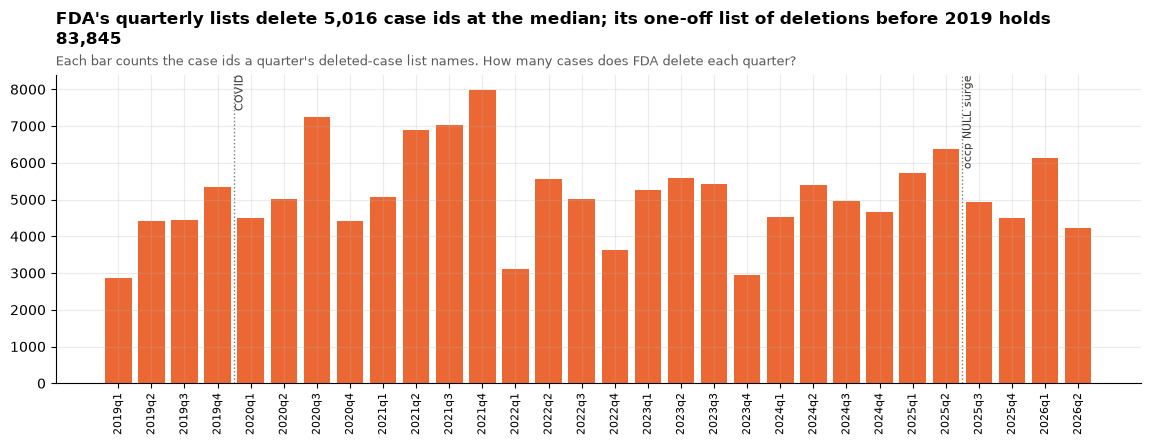

quarter_T,2019q1,2019q2,2019q3,2019q4,2020q1,2020q2,2020q3,2020q4,2021q1,2021q2,2021q3,2021q4,2022q1,2022q2,2022q3,2022q4,2023q1,2023q2,2023q3,2023q4,2024q1,2024q2,2024q3,2024q4,2025q1,2025q2,2025q3,2025q4,2026q1,2026q2
n,2856,4405,4455,5338,4489,5016,7238,4428,5067,6881,7033,7983,3118,5567,5016,3624,5251,5581,5433,2940,4530,5409,4969,4661,5732,6371,4947,4497,6135,4217


In [10]:
d = q("select quarter_T, count(*) n from deleted_all group by 1 order by 1")
hist = int(d[d.quarter_T == "pre2019q1"].n.sum())
dq = d[d.quarter_T != "pre2019q1"]
fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(range(len(dq)), dq.n, color=SERIES[1], width=0.8)
ax.set_xticks(range(len(dq)))
ax.set_xticklabels(dq.quarter_T, rotation=90, fontsize=8)
title(
    ax,
    f"FDA's quarterly lists delete {dq.n.median():,.0f} case ids at the median; its one-off list of "
    f"deletions before 2019 holds {hist:,}",
    "Each bar counts the case ids a quarter's deleted-case list names.",
    "How many cases does FDA delete each quarter?",
)
mark_quarters(ax, dq.quarter_T)
plt.show()
dq.set_index("quarter_T").T

## Senders (manufacturer) in the FAERS era

`mfr_sndr` is free text as submitted; the same company appears under several spellings. Concentration is the point here, not the exact names.

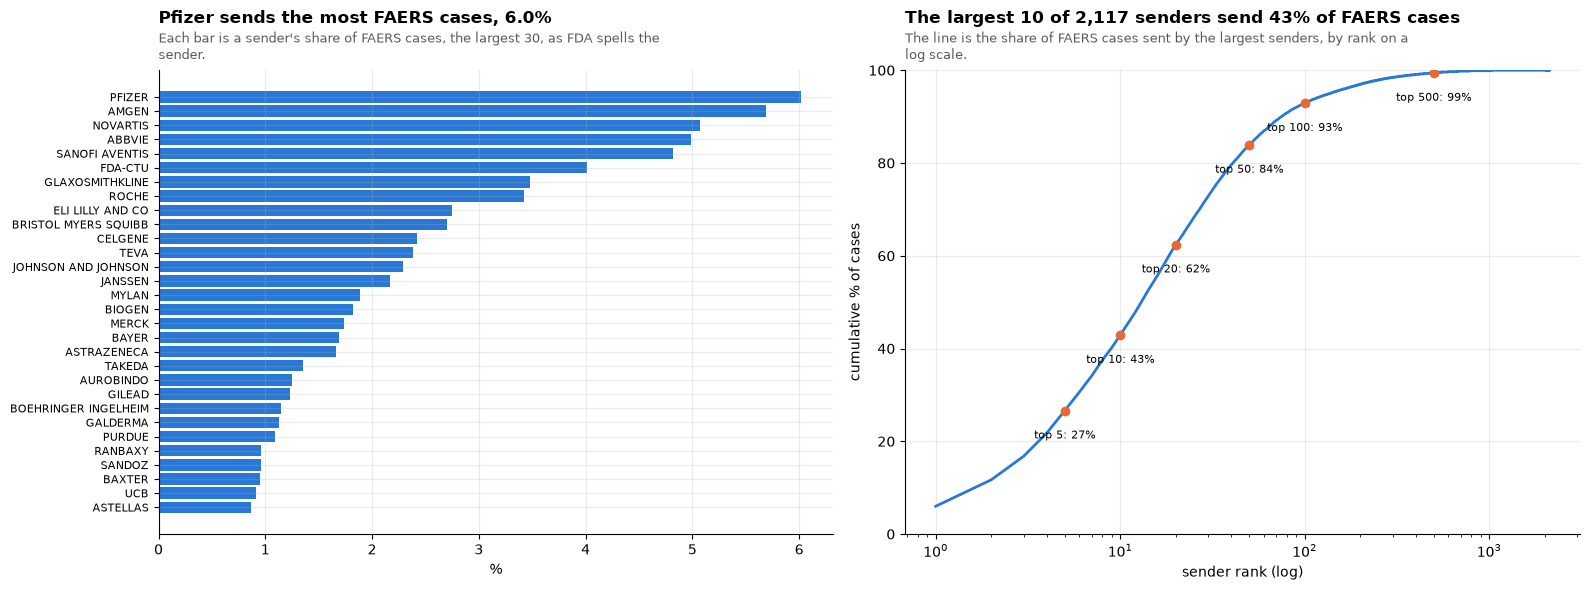

,mfr_sndr,n,pct,cum_pct
0,PFIZER,1058397,6.02,6.0
1,AMGEN,1000903,5.69,11.7
2,NOVARTIS,890889,5.07,16.8
3,ABBVIE,877547,4.99,21.8
4,SANOFI AVENTIS,847594,4.82,26.6
5,FDA-CTU,704730,4.01,30.6
6,GLAXOSMITHKLINE,611799,3.48,34.1
7,ROCHE,600696,3.42,37.5
8,ELI LILLY AND CO,483387,2.75,40.2
9,BRISTOL MYERS SQUIBB,474908,2.70,42.9


In [11]:
s = q("""with s as (select mfr_sndr, count(*) n from case_latest_T where era_T='faers' group by 1)
select mfr_sndr, n, round(100.0*n/sum(n) over(),2) pct, round(100.0*sum(n) over (order by n desc rows unbounded preceding)/sum(n) over(),1) cum_pct,
       row_number() over (order by n desc) rk from s order by n desc""")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 1]})
t30 = s.head(30)
a1.barh(t30.mfr_sndr[::-1], t30.pct[::-1], color=SERIES[0])
title(
    a1,
    f"{t30.mfr_sndr.iloc[0].title()} sends the most FAERS cases, {t30.pct.iloc[0]:.1f}%",
    "Each bar is a sender's share of FAERS cases, the largest 30, as FDA spells the sender.",
)
a1.set_xlabel("%")
a1.tick_params(axis="y", labelsize=8)
a2.plot(s.rk, s.cum_pct, color=SERIES[0])
a2.set_xscale("log")
a2.set_ylim(0, 100)
a2.set_xlabel("sender rank (log)")
a2.set_ylabel("cumulative % of cases")
top10 = s.loc[s.rk == 10, "cum_pct"].iloc[0]
title(
    a2,
    f"The largest 10 of {len(s):,} senders send {top10:.0f}% of FAERS cases",
    "The line is the share of FAERS cases sent by the largest senders, by rank on a log scale.",
)
for k in [5, 10, 20, 50, 100, 500]:
    y = s.loc[s.rk == k, "cum_pct"].iloc[0]
    a2.plot(k, y, "o", color=SERIES[1])
    a2.text(k, y - 6, f"top {k}: {y:.0f}%", fontsize=8, ha="center")
plt.tight_layout()
plt.show()
t30[["mfr_sndr", "n", "pct", "cum_pct"]]

## Methods-page cards from this notebook

The cards below are computed by the same functions the release build calls (`src/open_altio/faers/insights/cards`), so the chart data on the methods page is reproducible from this code. Each card is written to `notebooks/out/cards/` (or `$OPEN_ALTIO_INSIGHTS_OUT`) for checking; the release carries them in `methods.json`.

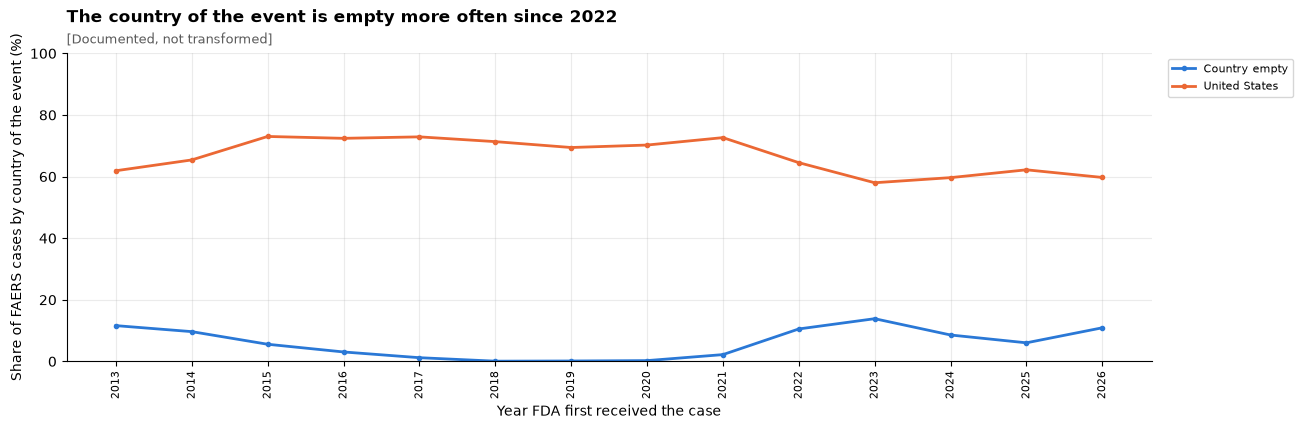

Cases with no country of occurrence almost disappear from 2017 to 2021, then come back from 2022 at 6% to 14% of FAERS cases a year, while the United States share falls from about 72% to about 60%. Country filters miss these cases; we document the gap and do not infer a country.
notebooks/out/cards/01_volume_over_time.json


In [12]:
from open_altio.faers.insights.cards import compute_cards
from open_altio.faers.insights.cards.notebook import plot_card, write_cards

cards = compute_cards(con, ["country_empty_rising"])
for card in cards:
    plot_card(card)
print(write_cards(cards, "01_volume_over_time"))